# First-Order Differential Equations

Notes with worked examples: analytical methods (separable, linear, exact), direction fields, an introduction to numerical methods, and applications.

**Contents**
1. Definitions and initial value problems
2. Direction fields
3. Separable equations
4. Linear equations (integrating factor)
5. Exact equations
6. Numerical methods: Euler and RK4 (the full treatment is in the [Numerical Methods chapter](numerical-methods/index.ipynb))
7. Applications: Newton's law of cooling, logistic growth
8. An equation with no elementary solution
9. Summary
10. Exercises

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.grid"] = True
np.set_printoptions(precision=6, suppress=True)

## 1. Definitions

A **first-order ordinary differential equation (ODE)** relates an unknown function $y(x)$ to its first derivative:

$$\frac{dy}{dx} = f(x, y).$$

An **initial value problem (IVP)** adds a starting condition:

$$\frac{dy}{dx} = f(x, y), \qquad y(x_0) = y_0.$$

* A **general solution** contains an arbitrary constant $C$ (a one-parameter family of curves).
* A **particular solution** is the member of that family that satisfies the initial condition.

**Existence and uniqueness (Picard's theorem).** If $f$ and $\partial f/\partial y$ are continuous in a rectangle containing $(x_0, y_0)$, the IVP has exactly one solution on some interval around $x_0$.

*Example where uniqueness fails:* $y' = 3y^{2/3}$, $y(0)=0$. Both $y = 0$ and $y = x^3$ are solutions, because $\partial f/\partial y = 2y^{-1/3}$ is not continuous at $y = 0$.

## 2. Direction fields

At every point $(x, y)$ the equation gives the slope $f(x,y)$ of the solution curve passing through it. Drawing short line segments with these slopes produces a **direction (slope) field**. Solution curves follow the arrows.

Below is the field for $y' = x - y$, with a few solution curves. The exact solution is $y = x - 1 + Ce^{-x}$, so every curve approaches the line $y = x - 1$.

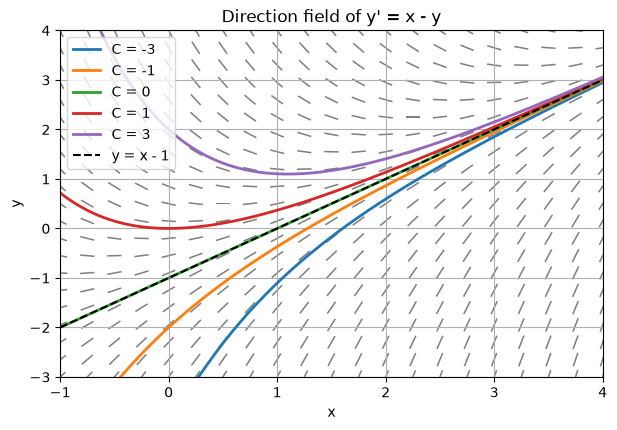

In [2]:
def direction_field(f, xlim, ylim, n=21, ax=None):
    # Draw normalised slope segments of y' = f(x, y).
    ax = ax or plt.gca()
    X, Y = np.meshgrid(np.linspace(*xlim, n), np.linspace(*ylim, n))
    S = f(X, Y)
    L = np.sqrt(1 + S**2)
    ax.quiver(X, Y, 1 / L, S / L, angles="xy", color="gray",
              headwidth=0, headlength=0, headaxislength=0, pivot="middle")
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_xlabel("x"); ax.set_ylabel("y")
    return ax

f = lambda x, y: x - y
ax = direction_field(f, (-1, 4), (-3, 4))
x = np.linspace(-1, 4, 200)
for C in [-3, -1, 0, 1, 3]:
    ax.plot(x, x - 1 + C * np.exp(-x), lw=2, label=f"C = {C}")
ax.plot(x, x - 1, "k--", label="y = x - 1")
ax.set_title("Direction field of y' = x - y")
ax.legend(loc="upper left");

## 3. Separable equations

An equation is **separable** if it can be written as

$$\frac{dy}{dx} = g(x)\,h(y).$$

**Method:** separate the variables and integrate both sides:

$$\int \frac{dy}{h(y)} = \int g(x)\,dx + C.$$

### Worked example 3.1

Solve $\dfrac{dy}{dx} = xy$, $y(0) = 1$.

1. Separate: $\dfrac{dy}{y} = x\,dx$.
2. Integrate: $\ln|y| = \dfrac{x^2}{2} + C$.
3. Solve for $y$: $y = Ae^{x^2/2}$.
4. Apply $y(0)=1$: $A = 1$, so $\boxed{y = e^{x^2/2}}$.

Check: $y' = x e^{x^2/2} = xy$. ✓  Numerically, $y(1) = e^{0.5} \approx 1.648721$.

### Worked example 3.2

Solve $\dfrac{dy}{dx} = \dfrac{x^2}{1 + y}$, $y(0) = 0$.

1. $(1 + y)\,dy = x^2\,dx$
2. $y + \dfrac{y^2}{2} = \dfrac{x^3}{3} + C$, and $y(0)=0$ gives $C = 0$.
3. Solve the quadratic $y^2 + 2y - \tfrac{2}{3}x^3 = 0$ and take the root through the origin:
   $\boxed{y = -1 + \sqrt{1 + \tfrac{2}{3}x^3}}$.

At $x = 1$: $y = -1 + \sqrt{5/3} \approx 0.290994$.

Example 3.1  y(1) = 1.6487212707001282
Example 3.2  y(1) = 0.2909944487358056


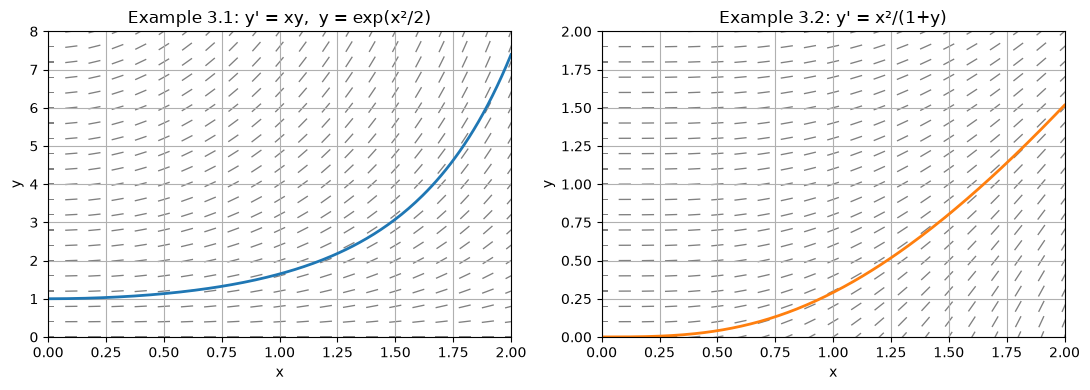

In [3]:
x = np.linspace(0, 2, 200)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

direction_field(lambda x, y: x * y, (0, 2), (0, 8), ax=axes[0])
axes[0].plot(x, np.exp(x**2 / 2), "C0", lw=2)
axes[0].set_title("Example 3.1: y' = xy,  y = exp(x²/2)")

direction_field(lambda x, y: x**2 / (1 + y), (0, 2), (0, 2), ax=axes[1])
axes[1].plot(x, -1 + np.sqrt(1 + 2 * x**3 / 3), "C1", lw=2)
axes[1].set_title("Example 3.2: y' = x²/(1+y)")
plt.tight_layout()

print("Example 3.1  y(1) =", np.exp(0.5))
print("Example 3.2  y(1) =", -1 + np.sqrt(5 / 3))

## 4. Linear first-order equations

Standard form:

$$\frac{dy}{dx} + P(x)\,y = Q(x).$$

**Method (integrating factor):**

1. Compute $\mu(x) = e^{\int P(x)\,dx}$.
2. Multiply through: $\mu y' + \mu P y = \mu Q$. The left side is exactly $(\mu y)'$.
3. Integrate: $\mu(x)\,y = \int \mu(x) Q(x)\,dx + C$.
4. Divide by $\mu$.

### Worked example 4.1

Solve $y' + y = x$, $y(0) = 1$.

1. $P = 1$, so $\mu = e^{x}$.
2. $(e^{x}y)' = x e^{x}$.
3. Integrate by parts: $e^{x}y = (x - 1)e^{x} + C$.
4. $y = x - 1 + Ce^{-x}$. From $y(0) = 1$: $-1 + C = 1$, so $C = 2$.

$$\boxed{y = x - 1 + 2e^{-x}}$$

### Worked example 4.2

Solve $x y' + 2y = 4x^2$, $y(1) = 2$, for $x > 0$.

1. Standard form: $y' + \dfrac{2}{x}y = 4x$, so $\mu = e^{2\ln x} = x^2$.
2. $(x^2 y)' = 4x^3$, so $x^2 y = x^4 + C$.
3. $y = x^2 + C/x^2$. From $y(1) = 2$: $C = 1$.

$$\boxed{y = x^2 + \frac{1}{x^2}}$$

In [4]:
xs = np.array([0.0, 0.5, 1.0, 1.5, 2.0])
print("Example 4.1:  y = x - 1 + 2e^(-x)")
print(f"{'x':>6} {'y(x)':>12}")
for xi in xs:
    print(f"{xi:6.2f} {xi - 1 + 2 * np.exp(-xi):12.6f}")

xs = np.array([1.0, 1.5, 2.0, 3.0])
print("\nExample 4.2:  y = x^2 + 1/x^2")
print(f"{'x':>6} {'y(x)':>12}")
for xi in xs:
    print(f"{xi:6.2f} {xi**2 + 1 / xi**2:12.6f}")

Example 4.1:  y = x - 1 + 2e^(-x)
     x         y(x)
  0.00     1.000000
  0.50     0.713061
  1.00     0.735759
  1.50     0.946260
  2.00     1.270671

Example 4.2:  y = x^2 + 1/x^2
     x         y(x)
  1.00     2.000000
  1.50     2.694444
  2.00     4.250000
  3.00     9.111111


## 5. Exact equations

An equation $M(x,y)\,dx + N(x,y)\,dy = 0$ is **exact** if

$$\frac{\partial M}{\partial y} = \frac{\partial N}{\partial x}.$$

Then there is a potential function $F(x,y)$ with $F_x = M$ and $F_y = N$, and the solution is $F(x, y) = C$.

### Worked example 5.1

Solve $(2xy + 3)\,dx + (x^2 - 1)\,dy = 0$, $y(0) = 2$.

1. Test: $M_y = 2x$, $N_x = 2x$. The equation is exact. ✓
2. Integrate $M$ with respect to $x$: $F = x^2 y + 3x + g(y)$.
3. Differentiate with respect to $y$ and match $N$: $x^2 + g'(y) = x^2 - 1$, so $g(y) = -y$.
4. Solution: $x^2 y + 3x - y = C$. From $y(0) = 2$: $C = -2$.

$$\boxed{y = \frac{-2 - 3x}{x^2 - 1} = \frac{3x + 2}{1 - x^2}}, \qquad -1 < x < 1.$$

At $x = 0.5$: $y = 3.5 / 0.75 \approx 4.666667$.

In [5]:
# Check example 5.1 by verifying that F(x, y(x)) stays equal to C = -2
y = lambda x: (3 * x + 2) / (1 - x**2)
F = lambda x, y: x**2 * y + 3 * x - y
for xi in [0.0, 0.25, 0.5, 0.75]:
    print(f"x = {xi:4.2f}   y = {y(xi):9.6f}   F(x, y) = {F(xi, y(xi)):.6f}")

x = 0.00   y =  2.000000   F(x, y) = -2.000000
x = 0.25   y =  2.933333   F(x, y) = -2.000000
x = 0.50   y =  4.666667   F(x, y) = -2.000000
x = 0.75   y =  9.714286   F(x, y) = -2.000000


## 6. Numerical methods

The methods of Sections 3–5 cover only special forms of $f(x, y)$; most equations, such as the one in Section 8, have no formula for their solution. A **numerical method** computes approximate values $y_n \approx y(x_n)$ on a grid $x_n = x_0 + nh$ with step size $h$. Two are used in the rest of this notebook:

| Method | Formula | Order (global error) |
|---|---|---|
| Euler | $y_{n+1} = y_n + h\,f(x_n, y_n)$ | $O(h)$ |
| Classical Runge–Kutta (RK4) | $y_{n+1} = y_n + \tfrac{h}{6}(k_1 + 2k_2 + 2k_3 + k_4)$ with $k_1 = f(x_n, y_n)$, $k_2 = f(x_n + \tfrac h2, y_n + \tfrac h2 k_1)$, $k_3 = f(x_n + \tfrac h2, y_n + \tfrac h2 k_2)$, $k_4 = f(x_n + h, y_n + hk_3)$ | $O(h^4)$ |

Derivations, error analysis and many more methods and examples are in the chapter **[Numerical Methods for First-Order ODEs](numerical-methods/index.ipynb)**:

1. [Euler's method](numerical-methods/01-eulers-method.ipynb)
2. [Second-order Runge–Kutta methods](numerical-methods/02-second-order-runge-kutta.ipynb)
3. [The classical Runge–Kutta method (RK4)](numerical-methods/03-runge-kutta-4.ipynb)
4. [Error, order and efficiency](numerical-methods/04-error-order-efficiency.ipynb)
5. [Stability and stiff equations](numerical-methods/05-stability-and-stiffness.ipynb)
6. [Adaptive step size](numerical-methods/06-adaptive-step-size.ipynb)
7. [Multistep methods](numerical-methods/07-multistep-methods.ipynb)
8. [Systems and higher-order equations](numerical-methods/08-systems-and-higher-order.ipynb)

In [6]:
def euler(f, x0, y0, h, n):
    x, y = np.zeros(n + 1), np.zeros(n + 1)
    x[0], y[0] = x0, y0
    for i in range(n):
        y[i + 1] = y[i] + h * f(x[i], y[i])
        x[i + 1] = x[i] + h
    return x, y

def rk4(f, x0, y0, h, n):
    x, y = np.zeros(n + 1), np.zeros(n + 1)
    x[0], y[0] = x0, y0
    for i in range(n):
        k1 = f(x[i], y[i])
        k2 = f(x[i] + h / 2, y[i] + h / 2 * k1)
        k3 = f(x[i] + h / 2, y[i] + h / 2 * k2)
        k4 = f(x[i] + h, y[i] + h * k3)
        y[i + 1] = y[i] + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        x[i + 1] = x[i] + h
    return x, y

**Example.** $y' = x + y$, $y(0) = 1$ is linear, so the method of Section 4 gives its exact solution $y = 2e^{x} - x - 1$. With $h = 0.1$:

y(1): exact 3.43656366   Euler 3.18748492 (error 2.5e-01)   RK4 3.43655949 (error 4.2e-06)


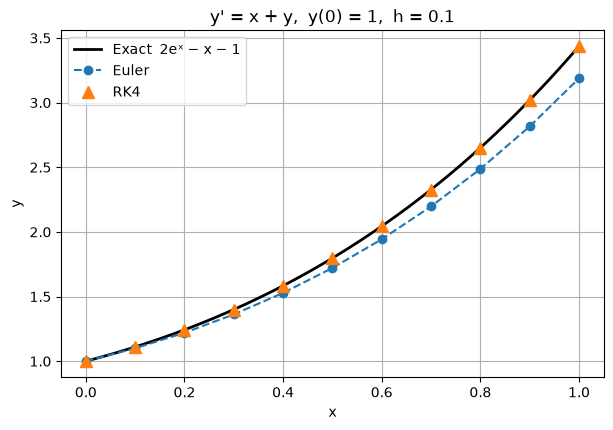

In [7]:
f = lambda x, y: x + y
exact = lambda x: 2 * np.exp(x) - x - 1

x, ye = euler(f, 0, 1, 0.1, 10)
_, yr = rk4(f, 0, 1, 0.1, 10)
print(f"y(1): exact {exact(1):.8f}   Euler {ye[-1]:.8f} (error {exact(1) - ye[-1]:.1e})   RK4 {yr[-1]:.8f} (error {exact(1) - yr[-1]:.1e})")

xf = np.linspace(0, 1, 200)
plt.plot(xf, exact(xf), "k", lw=2, label="Exact  2eˣ − x − 1")
plt.plot(x, ye, "o--", label="Euler")
plt.plot(x, yr, "^", ms=8, label="RK4")
plt.title("y' = x + y,  y(0) = 1,  h = 0.1")
plt.xlabel("x"); plt.ylabel("y"); plt.legend();

## 7. Applications

### 7.1 Newton's law of cooling

The rate of temperature change is proportional to the difference from the surroundings:

$$\frac{dT}{dt} = -k\,(T - T_a).$$

**Problem.** A cup of coffee at $90^\circ$C is placed in a $20^\circ$C room with $k = 0.1\ \text{min}^{-1}$.
(a) What is its temperature after 10 minutes? (b) When does it reach $30^\circ$C?

The equation is separable (and linear): $T(t) = T_a + (T_0 - T_a)e^{-kt} = 20 + 70e^{-0.1t}$.

(a) $T(10) = 20 + 70e^{-1} \approx 20 + 25.752 = 45.75^\circ$C.

(b) $20 + 70e^{-0.1t} = 30 \Rightarrow e^{-0.1t} = 1/7 \Rightarrow t = 10\ln 7 \approx 19.46$ min.

T(10) exact = 45.7516   RK4 = 45.7516   Euler = 44.4075
time to reach 30 °C = 10 ln 7 = 19.4591 min


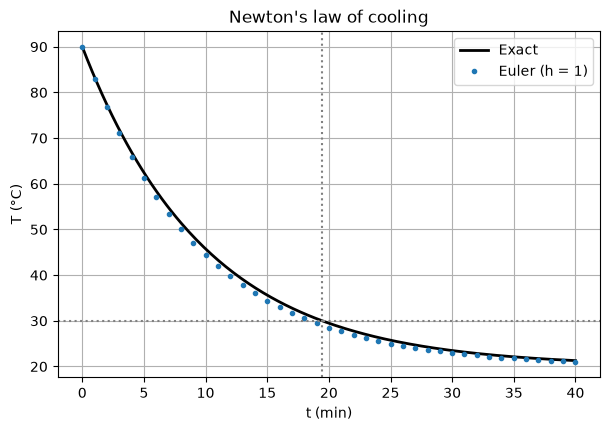

In [8]:
k, Ta, T0 = 0.1, 20.0, 90.0
cool = lambda t, T: -k * (T - Ta)
T_exact = lambda t: Ta + (T0 - Ta) * np.exp(-k * t)

t, T_rk = rk4(cool, 0, T0, 1.0, 40)       # h = 1 minute
_, T_eu = euler(cool, 0, T0, 1.0, 40)

print(f"T(10) exact = {T_exact(10):.4f}   RK4 = {T_rk[10]:.4f}   Euler = {T_eu[10]:.4f}")
print(f"time to reach 30 °C = 10 ln 7 = {10 * np.log(7):.4f} min")

tf = np.linspace(0, 40, 200)
plt.plot(tf, T_exact(tf), "k", lw=2, label="Exact")
plt.plot(t, T_eu, ".", label="Euler (h = 1)")
plt.axhline(30, color="gray", ls=":"); plt.axvline(10 * np.log(7), color="gray", ls=":")
plt.xlabel("t (min)"); plt.ylabel("T (°C)"); plt.title("Newton's law of cooling")
plt.legend();

### 7.2 Logistic population growth

$$\frac{dP}{dt} = rP\left(1 - \frac{P}{K}\right),$$

where $r$ is the growth rate and $K$ is the carrying capacity. Separating variables with partial fractions gives

$$P(t) = \frac{K}{1 + \left(\dfrac{K - P_0}{P_0}\right)e^{-rt}}.$$

**Problem.** $r = 0.5$ per year, $K = 1000$, $P_0 = 100$. Find $P(5)$.

$$P(5) = \frac{1000}{1 + 9e^{-2.5}} = \frac{1000}{1 + 9(0.082085)} = \frac{1000}{1.738765} \approx 575.1.$$

The equilibria are $P = 0$ (unstable) and $P = K$ (stable). Growth is fastest at $P = K/2$.

P(5) exact = 575.1209   RK4 (h=0.5) = 575.1165


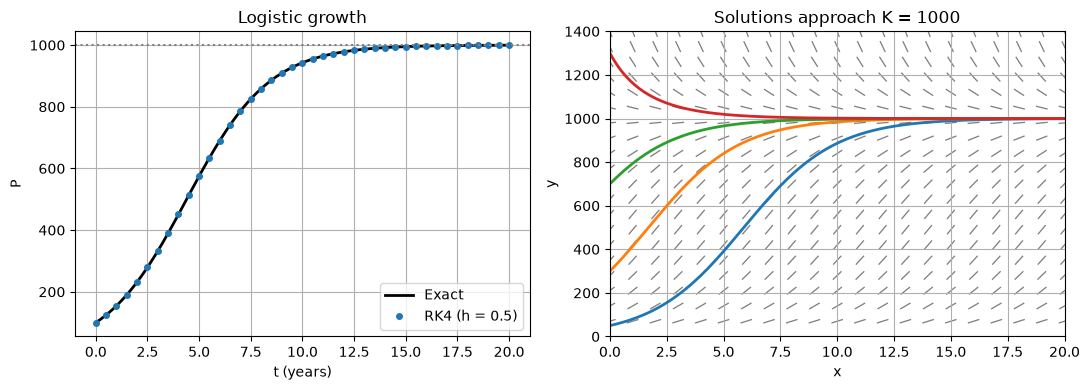

In [9]:
r, K, P0 = 0.5, 1000.0, 100.0
logistic = lambda t, P: r * P * (1 - P / K)
P_exact = lambda t: K / (1 + (K - P0) / P0 * np.exp(-r * t))

t, P_rk = rk4(logistic, 0, P0, 0.5, 40)
print(f"P(5) exact = {P_exact(5):.4f}   RK4 (h=0.5) = {P_rk[10]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
tf = np.linspace(0, 20, 200)
axes[0].plot(tf, P_exact(tf), "k", lw=2, label="Exact")
axes[0].plot(t, P_rk, "o", ms=4, label="RK4 (h = 0.5)")
axes[0].axhline(K, color="gray", ls=":"); axes[0].set_title("Logistic growth")
axes[0].set_xlabel("t (years)"); axes[0].set_ylabel("P"); axes[0].legend()

direction_field(logistic, (0, 20), (0, 1400), ax=axes[1])
for p0 in [50, 300, 700, 1300]:
    _, Pp = rk4(logistic, 0, p0, 0.1, 200)
    axes[1].plot(np.linspace(0, 20, 201), Pp, lw=2)
axes[1].set_title("Solutions approach K = 1000")
plt.tight_layout()

## 8. An equation with no elementary solution

The Riccati equation

$$y' = x^2 + y^2, \qquad y(0) = 0$$

cannot be solved in terms of elementary functions. We estimate $y(1)$ with RK4 and check the result by repeatedly halving $h$. When the digits stop changing, the answer has converged.

In [10]:
g = lambda x, y: x**2 + y**2

prev = None
print(f"{'h':>8} {'y(1) RK4':>16} {'change':>12}")
for h in [0.2, 0.1, 0.05, 0.025, 0.0125]:
    _, y = rk4(g, 0, 0, h, round(1 / h))
    change = f"{abs(y[-1] - prev):12.2e}" if prev is not None else ""
    print(f"{h:8.4f} {y[-1]:16.10f} {change}")
    prev = y[-1]

       h         y(1) RK4       change
  0.2000     0.3502575491 
  0.1000     0.3502337418     2.38e-05
  0.0500     0.3502319725     1.77e-06
  0.0250     0.3502318526     1.20e-07
  0.0125     0.3502318448     7.79e-09


The last two values agree to about 8 significant figures: $y(1) \approx 0.3502318$. The solution grows quickly afterwards and blows up near $x \approx 2.003$, a reminder that solutions of nonlinear ODEs can exist only on a finite interval.

## 9. Summary

| Type | Form | Method |
|---|---|---|
| Separable | $y' = g(x)h(y)$ | $\int dy/h = \int g\,dx$ |
| Linear | $y' + P y = Q$ | Integrating factor $\mu = e^{\int P}$ |
| Exact | $M\,dx + N\,dy = 0$, $M_y = N_x$ | Find $F$ with $F_x = M$, $F_y = N$; then $F = C$ |
| Anything else | $y' = f(x,y)$ | Numerical: Euler (order 1), RK4 (order 4); see [Numerical Methods](numerical-methods/index.ipynb) |

## 10. Exercises

1. Solve $y' = y\cos x$, $y(0) = 2$.
2. Solve $y' - 3y = e^{2x}$, $y(0) = 0$.
3. Show that $(y e^{x} + 2x)\,dx + (e^{x} - 1)\,dy = 0$ is exact and solve it with $y(1) = 0$.
4. Use Euler with $h = 0.25$ to estimate $y(1)$ for $y' = -2xy$, $y(0) = 1$. Compare with the exact value $e^{-1}$.
5. Repeat Exercise 4 with RK4 and $h = 0.25$. How many times smaller is the error?

**Answers**

1. $y = 2e^{\sin x}$
2. $y = e^{3x} - e^{2x}$
3. $M_y = e^{x} = N_x$; $F = ye^{x} + x^2 - y$, so $ye^{x} + x^2 - y = 1$, giving $y = \dfrac{1 - x^2}{e^{x} - 1}$.
4. and 5. Run the cell below.

In [11]:
q = lambda x, y: -2 * x * y
_, y_eu = euler(q, 0, 1, 0.25, 4)
_, y_rk = rk4(q, 0, 1, 0.25, 4)
ex = np.exp(-1)
print(f"Exact  y(1) = {ex:.6f}")
print(f"Euler  y(1) = {y_eu[-1]:.6f}   error = {abs(y_eu[-1] - ex):.2e}")
print(f"RK4    y(1) = {y_rk[-1]:.6f}   error = {abs(y_rk[-1] - ex):.2e}")
print(f"Error ratio Euler / RK4 ≈ {abs(y_eu[-1] - ex) / abs(y_rk[-1] - ex):.0f}")

Exact  y(1) = 0.367879
Euler  y(1) = 0.410156   error = 4.23e-02
RK4    y(1) = 0.367934   error = 5.51e-05
Error ratio Euler / RK4 ≈ 768
